# Chapitre 18 - Problèmes en grande dimension ($p \gg N$)
## Cours 3 : ACP supervisée, tests multiples et taux de fausses découvertes

Plan (sections 18.6 et 18.7 du livre) :

1. **composantes principales supervisées** : régression en grande dimension via une
   variable latente ; comparaison avec la PLS, et « pré-conditionnement » du lasso ;
2. **évaluation des variables** et problème des **tests multiples** : FWER, Bonferroni,
   taux de fausses découvertes (FDR), procédure de **Benjamini-Hochberg**, estimation
   « plug-in » par permutations, procédure **SAM**, interprétation bayésienne.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl import ch18_grande_dimension as g

## 1. Composantes principales supervisées (section 18.6)

### 1.1 Le modèle à variable latente

Le livre motive la méthode par un exemple de survie (lymphomes) : on imagine deux
« types cellulaires » ; les patients du bon type vivent plus longtemps en moyenne.
Le type cellulaire n'est pas observé, mais il se reflète dans l'expression de tout un
**groupe** de gènes (une voie biologique). Formellement (éq. (18.32)-(18.33)) :
$$Y = \beta_0 + \beta_1 U + \varepsilon, \qquad X_j = \alpha_{0j} + \alpha_{1j}U + \epsilon_j,\quad j\in\mathcal P,$$
où $U$ est une **variable latente** (le « type cellulaire » continu), $\mathcal P$
l'ensemble des gènes de la voie, et les autres gènes $X_k$, $k\notin\mathcal P$, sont
indépendants de $U$. Les erreurs sont centrées et indépendantes de tout le reste.

> **Intuition.** Chaque gène de $\mathcal P$ est une **mesure bruitée** de $U$. En
> moyennant beaucoup de ces mesures (c'est ce que fait la première composante
> principale de $\mathbf X_{\mathcal P}$), on estime $U$ bien mieux qu'avec un seul gène,
> puis on régresse $Y$ sur cette estimation.

### 1.2 L'algorithme (algorithme 18.1)

1. Pour chaque variable $j$, calculer le coefficient de régression **univarié
   standardisé** de $y$ sur $x_j$ (une statistique $t$).
2. Pour chaque seuil $\theta$ d'une grille $0\le\theta_1<\dots<\theta_K$ :
   - (a) ne garder que les variables dont $|$score$| > \theta$ et calculer les $m$
     premières composantes principales de cette matrice réduite ;
   - (b) utiliser ces composantes dans un modèle de régression pour prédire $y$.
3. Choisir $\theta$ (et $m$) par validation croisée.

Lien avec le modèle latent : l'étape 1 estime $\mathcal P$, l'étape 2a estime $U$, et
l'étape 2b estime $\beta_0,\beta_1$. Le plus souvent $m = 1$.

### 1.3 La simulation du livre (éq. (18.37))

$N = 100$ échantillons, $p = 5000$ gènes ; $\epsilon_{ij}\sim\mathcal N(0,1)$ et
$\varepsilon_i\sim\mathcal N(0, 1.5^2)$ :

- gènes $1$ à $50$ : moyenne $3$ pour les échantillons $1$–$50$, $4$ pour $51$–$100$ ;
- gènes $51$ à $250$ : moyenne $1.5$ pour les échantillons $1$–$25$ et $51$–$75$,
  $5.5$ pour les autres ;
- gènes $251$ à $5000$ : bruit pur ;
- $y_i = 2\cdot\frac1{50}\sum_{j=1}^{50}x_{ij} + \varepsilon_i$.

Les 50 premiers gènes portent un écart modéré **lié à $y$** ; les 200 suivants un écart
**beaucoup plus grand** (4 unités) mais **sans lien** avec $y$.

In [2]:
def simulate_spca(rng, N=100, p=5000):
    """Un jeu de données du modèle (18.37)."""
    X = rng.randn(N, p)
    i = np.arange(N)
    X[:, :50] += np.where(i < 50, 3.0, 4.0)[:, None]
    X[:, 50:250] += np.where((i % 50) < 25, 1.5, 5.5)[:, None]
    y = 2 * X[:, :50].mean(1) + 1.5 * rng.randn(N)
    return X, y


rng = np.random.RandomState(0)
X_s, y_s = simulate_spca(rng)

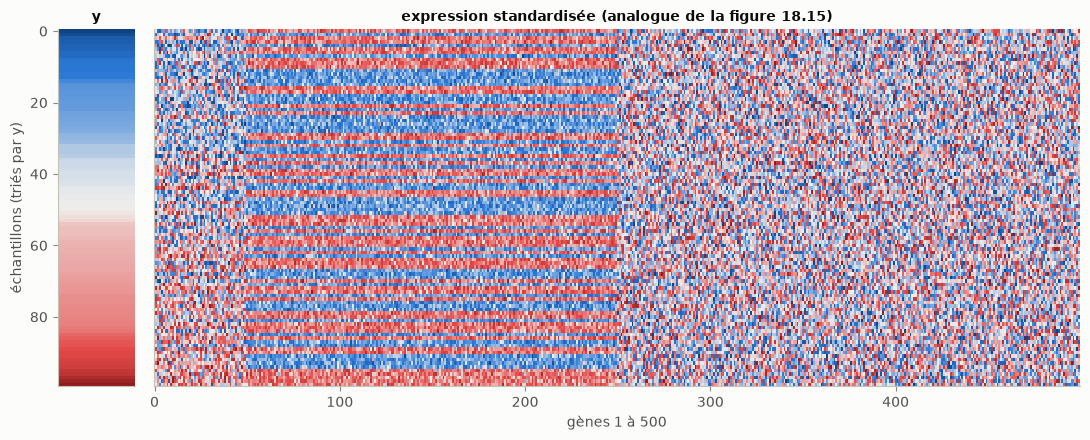

In [3]:
order_rows = np.argsort(y_s)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1, 12]})
axes[0].imshow(y_s[order_rows][:, None], aspect="auto", cmap=DIV, interpolation="nearest")
axes[0].set_xticks([])
axes[0].set_ylabel("échantillons (triés par y)")
axes[0].set_title("y", fontsize=10)
Xshow = X_s[order_rows][:, :500]
Xshow = (Xshow - Xshow.mean(0)) / Xshow.std(0)
axes[1].imshow(Xshow, aspect="auto", cmap=DIV, vmin=-2.5, vmax=2.5, interpolation="nearest")
axes[1].set_xlabel("gènes 1 à 500")
axes[1].set_yticks([])
axes[1].set_title("expression standardisée (analogue de la figure 18.15)", fontsize=10)
for ax in axes:
    ax.grid(False)
plt.tight_layout()
plt.show()

Les gènes 51–250 (au centre) dessinent un motif très visible (deux groupes
d'échantillons alternés) mais sans rapport avec $y$ ; les gènes 1–50 (à gauche)
suivent faiblement l'ordre de $y$.

**Pourquoi l'ACP ordinaire échoue.** La première composante principale cherche la
direction de **plus grande variance** : ici celle des gènes 51–250 (écart de 4 unités
sur 200 gènes). Elle n'a rien à voir avec $y$. La sélection supervisée (étape 1)
élimine ces gènes avant de calculer la composante.

In [ ]:
sc = g.univariate_scores(X_s, y_s)
Xc = X_s - X_s.mean(0)
pc1_all = Xc @ np.linalg.svd(Xc, full_matrices=False)[2][0]
spca = g.SupervisedPCA(n_features=50).fit(X_s, y_s, scores=sc)
pc1_sup = spca.transform(X_s)[:, 0]
print("gènes retenus parmi les 50 vrais :", np.sum(spca.selected_ < 50), "/ 50")
print(f"corrélation(y, CP1 de tous les gènes)        = {abs(np.corrcoef(y_s, pc1_all)[0, 1]):.2f}")
print(f"corrélation(y, CP1 supervisée, 50 gènes)     = {abs(np.corrcoef(y_s, pc1_sup)[0, 1]):.2f}")

### 1.4 Lien avec les moindres carrés partiels (PLS)

On suppose les variables standardisées. La première variable PLS (section 3.5.2)
restreinte aux variables sélectionnées est (éq. (18.34))
$z = \sum_{j\in\mathcal P}\langle y, x_j\rangle\,x_j$ : chaque gène est pondéré par sa
covariance avec $y$ (« PLS seuillée »). La composante supervisée $\hat u$ vérifie au
contraire (éq. (18.35))
$$\hat u = \frac1{d^2}\sum_{j\in\mathcal P}\langle\hat u, x_j\rangle\,x_j ,$$
où $d$ est la plus grande valeur singulière de $\mathbf X_{\mathcal P}$.

**Démonstration de (18.35).** Soit $\mathbf X_{\mathcal P} = \mathbf U\mathbf D\mathbf V^T$
et $\hat u = u_1$ la première colonne de $\mathbf U$ (composante normalisée). Par
définition de la SVD, $\mathbf X_{\mathcal P}\mathbf X_{\mathcal P}^T u_1 = d^2u_1$. Or
$\mathbf X_{\mathcal P}\mathbf X_{\mathcal P}^T = \sum_{j\in\mathcal P}x_jx_j^T$ (somme
sur les colonnes), donc
$d^2 u_1 = \sum_j x_j(x_j^Tu_1) = \sum_j\langle u_1, x_j\rangle x_j$. $\square$

Les poids de la PLS dépendent du seul $y$ (bruité) ; ceux de $\hat u$ sont
**auto-cohérents** et s'appuient sur tous les gènes de $\mathcal P$ : on peut montrer
(éq. (18.36)) que $z = u + O_p(1)$ alors que $\hat u = u + O_p(\sqrt{p_1/N})$.